# 02 · Modelagem, validação e interpretabilidade

Rode antes: `python -m src.preprocessing.build_dataset`, `python -m src.modeling.train` e `python -m src.evaluation.run_evaluation`.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.config import *
from src.preprocessing.build_dataset import carrega_gold, constroi, colunas_features
from src.visualization import plots
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
import json
M = json.loads((REPORTS / "metricas_finais.json").read_text())
R = json.loads((REPORTS / "resumo_avaliacao.json").read_text())

## 1. Comparação de modelos (validação cruzada estratificada, 5 folds, só no treino)

In [2]:
cmp = pd.read_csv(REPORTS / "comparacao_modelos_cv.csv")
display(cmp.drop(columns="melhores_params").round(4))
print("modelo escolhido:", M["modelo"])

,modelo,cv_roc_auc,cv_pr_auc,cv_f1,cv_accuracy,cv_roc_auc_std,cv_f1_std,train_roc_auc
0,gradient_boosting,0.7791,0.7580,0.6544,0.6973,0.0124,0.0171,0.8298
1,random_forest,0.7748,0.7547,0.6304,0.6877,0.0133,0.0170,0.8181
2,logreg,0.7744,0.7586,0.6452,0.6913,0.0141,0.0215,0.7833
3,dummy,0.5000,0.4609,0.0000,0.5391,0.0000,0.0000,NaN


modelo escolhido: gradient_boosting


O Gradient Boosting vence por margem pequena sobre a Regressão Logística. A diferença é menor que o desvio entre folds, então **o modelo simples é praticamente tão bom**, o que é um sinal de que o sinal está concentrado em poucas variáveis.

## 2. Desempenho no hold-out de teste (separado antes de qualquer ajuste)

,accuracy,precision_risco,recall_risco,f1_risco,roc_auc,pr_auc,brier
teste @0.5,0.7259,0.7379,0.6294,0.6793,0.8055,0.7850,0.1811
teste @0.35 (limiar via OOF),0.6905,0.6164,0.8716,0.7221,0.8055,0.7850,0.1811
treino @0.5,0.7376,0.7417,0.6610,0.6990,0.8233,0.8057,0.1716


,accuracy,f1_risco,roc_auc,pr_auc
dummy,0.5387,0.0000,0.5000,0.4613
logreg,0.7240,0.6814,0.8035,0.7812


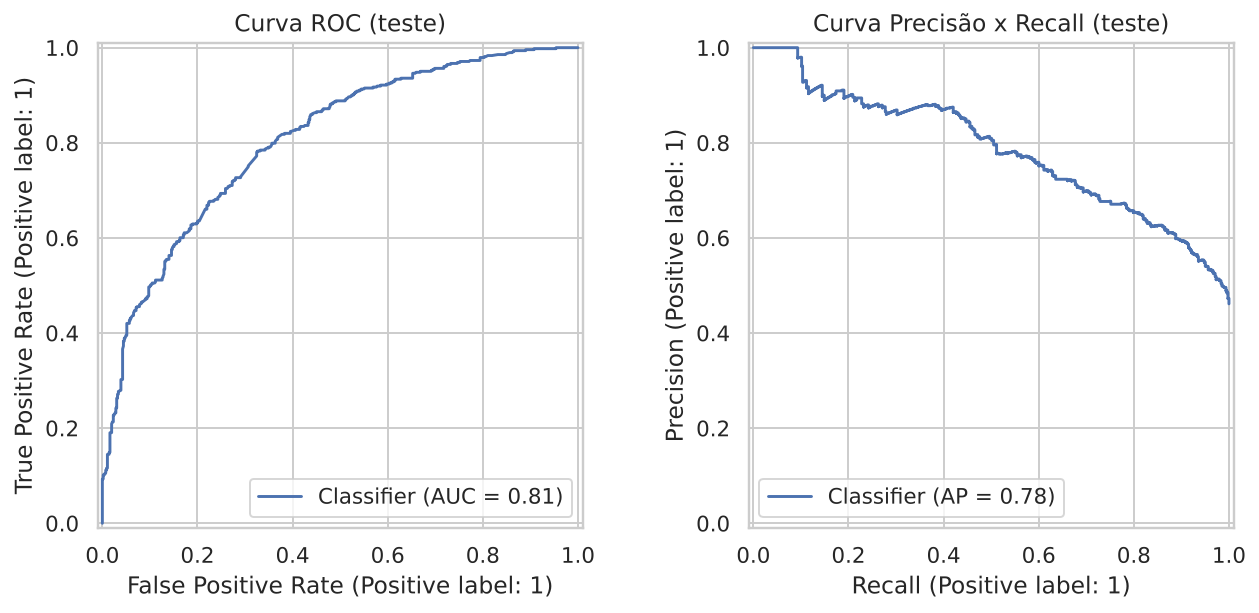

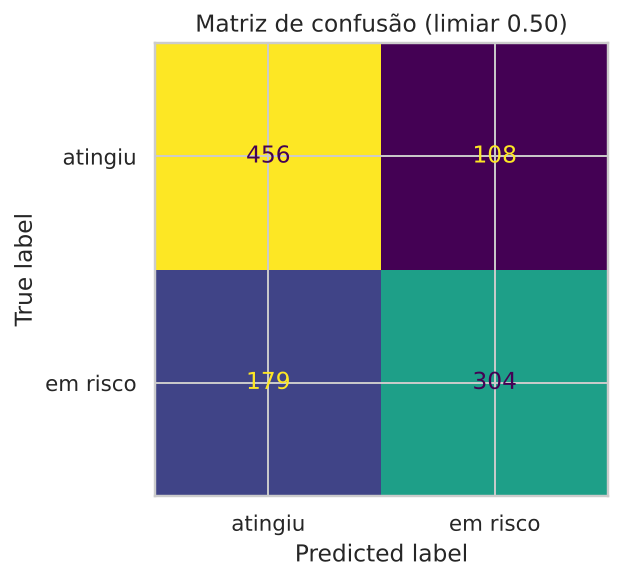

In [3]:
tab = pd.DataFrame({"teste @0.5": M["teste_limiar_0.5"], f"teste @{M['limiar_otimo_oof']:.2f} (limiar via OOF)": M["teste_limiar_otimo"],
                    "treino @0.5": M["treino_limiar_0.5"]}).T
display(tab[["accuracy", "precision_risco", "recall_risco", "f1_risco", "roc_auc", "pr_auc", "brier"]].round(4))
display(pd.DataFrame(M["baselines_teste"]).T[["accuracy", "f1_risco", "roc_auc", "pr_auc"]].round(4))
display(Image(str(IMAGES / "modelo_roc_pr.png"))); display(Image(str(IMAGES / "modelo_matriz_confusao.png")))

## 3. Generalização e overfitting

In [4]:
print("gap ROC-AUC treino - teste:", round(M["gap_roc_auc_treino_vs_teste"], 4))
print("CV aleatória (treino):", cmp.iloc[0][["cv_roc_auc", "cv_f1"]].round(4).to_dict())
print("CV POR UF (estados não vistos):", {k: round(v, 4) for k, v in M["cv_por_uf_treino"].items()})

gap ROC-AUC treino - teste: 0.0178
CV aleatória (treino): {'cv_roc_auc': 0.7791, 'cv_f1': 0.6544}
CV POR UF (estados não vistos): {'roc_auc': 0.5622, 'pr_auc': 0.5119, 'f1': 0.4314, 'accuracy': 0.5348}


**Leitura honesta:** o gap treino↔teste é pequeno (sem overfitting no sentido clássico), **mas o ROC-AUC cai para ≈0,56 quando o modelo é avaliado em UFs que nunca viu**. Ou seja: o modelo aprende em grande parte *o padrão de metas de cada estado*. Ele é útil para **monitorar municípios dentro de UFs conhecidas**, mas não deve ser usado para prever um estado novo.

## 4. Interpretabilidade: Feature Importance, Permutation Importance e SHAP

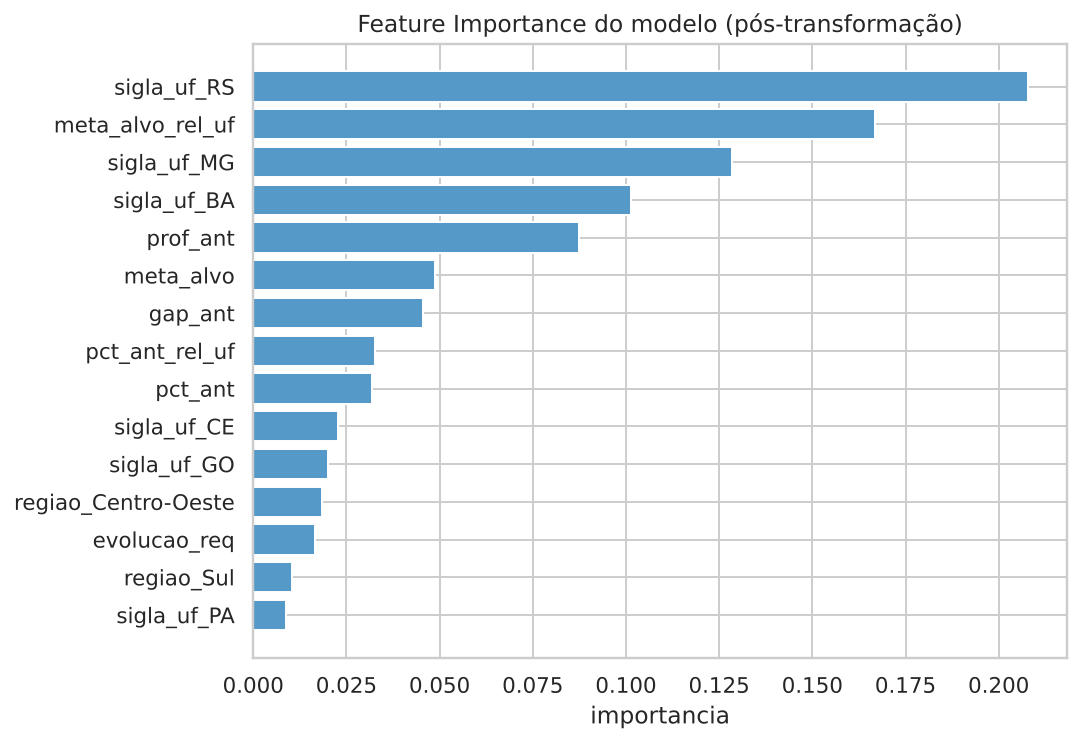

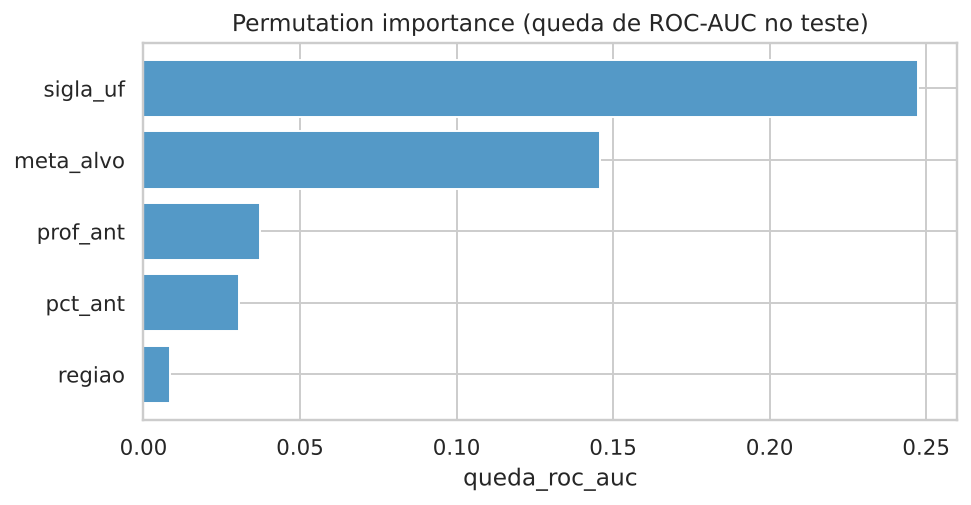

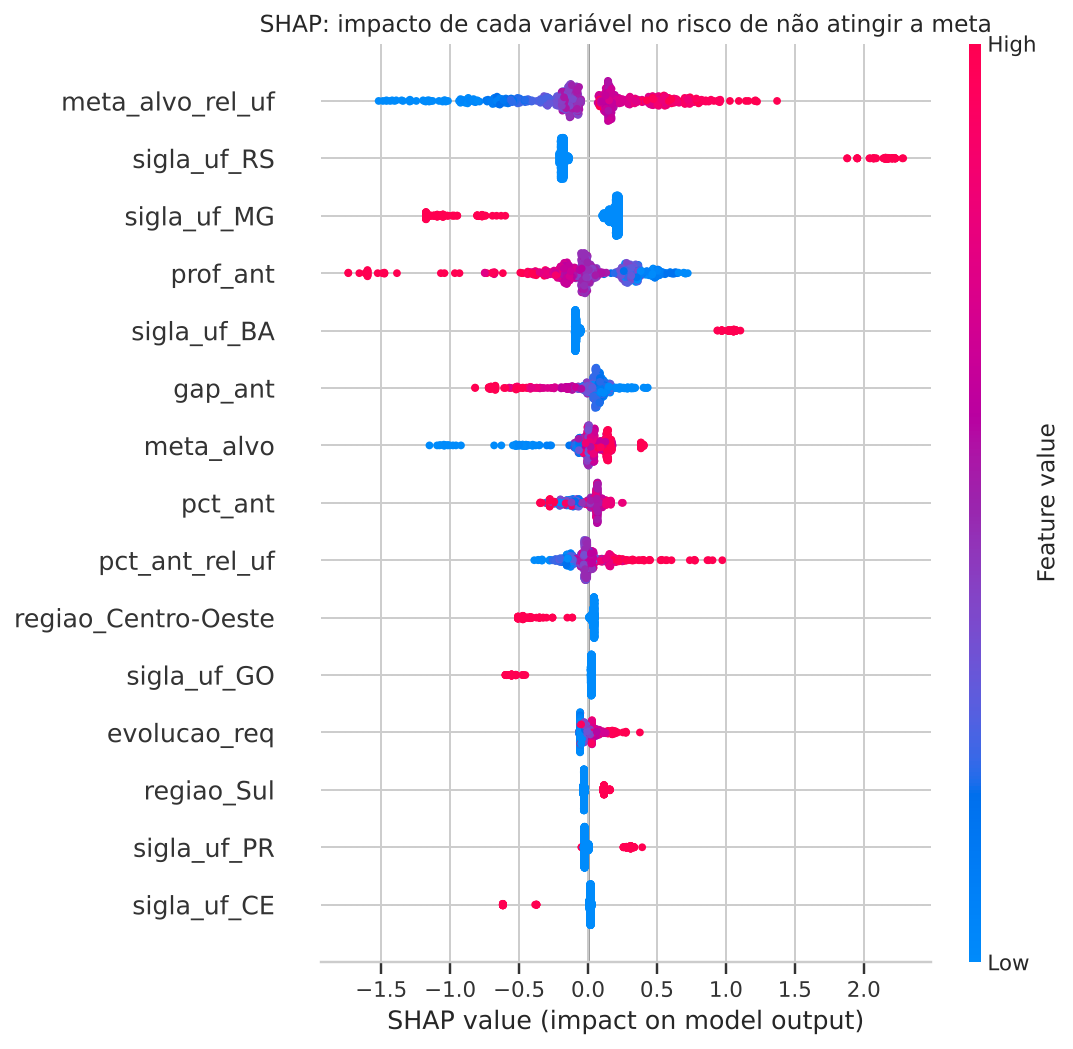

,feature,queda_roc_auc,desvio
0,sigla_uf,0.2475,0.0113
1,meta_alvo,0.1458,0.0120
2,prof_ant,0.0372,0.0072
3,pct_ant,0.0306,0.0066
4,regiao,0.0085,0.0031


In [5]:
for f in ["modelo_importancia_nativa.png", "modelo_importancia_permutacao.png", "shap_summary.png"]:
    display(Image(str(IMAGES / f)))
display(pd.read_csv(REPORTS / "importancia_permutacao.csv").head(8).round(4))

A **UF** e a **meta de 2024** concentram quase todo o poder preditivo; depois vêm proficiência e percentual de 2023. Regiões e variáveis derivadas contribuem pouco.

## 5. Municípios de maior risco

In [6]:
risco = pd.read_csv(REPORTS / "risco_municipios_2024.csv")
display(risco.head(15).round(3))
display(pd.read_csv(REPORTS / "risco_por_uf.csv").head(10))

,id_municipio,nome_municipio,sigla_uf,regiao,pct_ant,meta_alvo,pct_alvo,risco_nao_atingir_meta,prob_risco
0,4314498,Pinheirinho do Vale,RS,Sul,66.027,80.00,74.206,1,0.983
1,4300208,Ajuricaba,RS,Sul,69.337,80.00,74.319,1,0.976
2,4311254,Lagoão,RS,Sul,70.163,80.00,66.917,1,0.971
3,4319125,São Martinho da Serra,RS,Sul,66.509,77.00,35.653,1,0.970
4,4307500,Espumoso,RS,Sul,69.191,80.00,50.611,1,0.969
5,4308409,Formigueiro,RS,Sul,72.926,80.00,56.908,1,0.966
6,4312252,Minas do Leão,RS,Sul,65.871,74.31,55.499,1,0.964
7,2909000,Cordeiros,BA,Nordeste,69.321,71.03,52.459,1,0.961
8,4312807,Nova Araçá,RS,Sul,82.281,80.00,60.562,1,0.961
9,4312443,Morrinhos do Sul,RS,Sul,78.987,80.00,64.394,1,0.959


,sigla_uf,municipios,risco_medio,pct_em_risco_real,pct_prob_acima_70
0,RS,421,0.896,0.917,0.979
1,BA,394,0.797,0.810,0.832
2,PA,136,0.648,0.662,0.434
3,AM,48,0.586,0.604,0.312
4,RJ,90,0.573,0.600,0.022
5,AP,16,0.541,0.625,0.188
6,PR,395,0.516,0.532,0.008
7,RN,139,0.513,0.511,0.223
8,SE,75,0.502,0.467,0.200
9,SC,238,0.479,0.458,0.021


As probabilidades vêm de predição *out-of-fold*: nenhum município é previsto por um modelo que viu o próprio rótulo.

## 6. Regiões com padrões semelhantes (K-Means)

,Unnamed: 0,silhouette
0,2,0.417557
1,3,0.360548
2,4,0.348484
3,5,0.320768
4,6,0.306718
5,7,0.311432
6,8,0.298714


,grupo,n_municipios,taxa_risco,pct_ant,pct_alvo,prof_ant,prof_alvo,meta_alvo
0,0,3033,0.389,73.644,75.189,761.910,762.756,73.90
1,1,2199,0.560,43.115,47.896,732.248,737.082,49.79


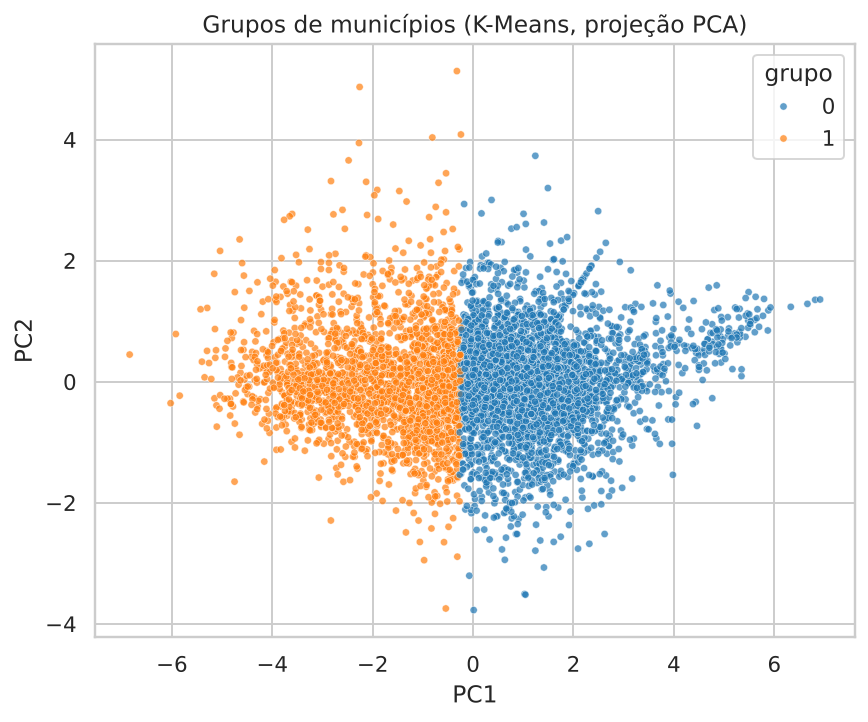

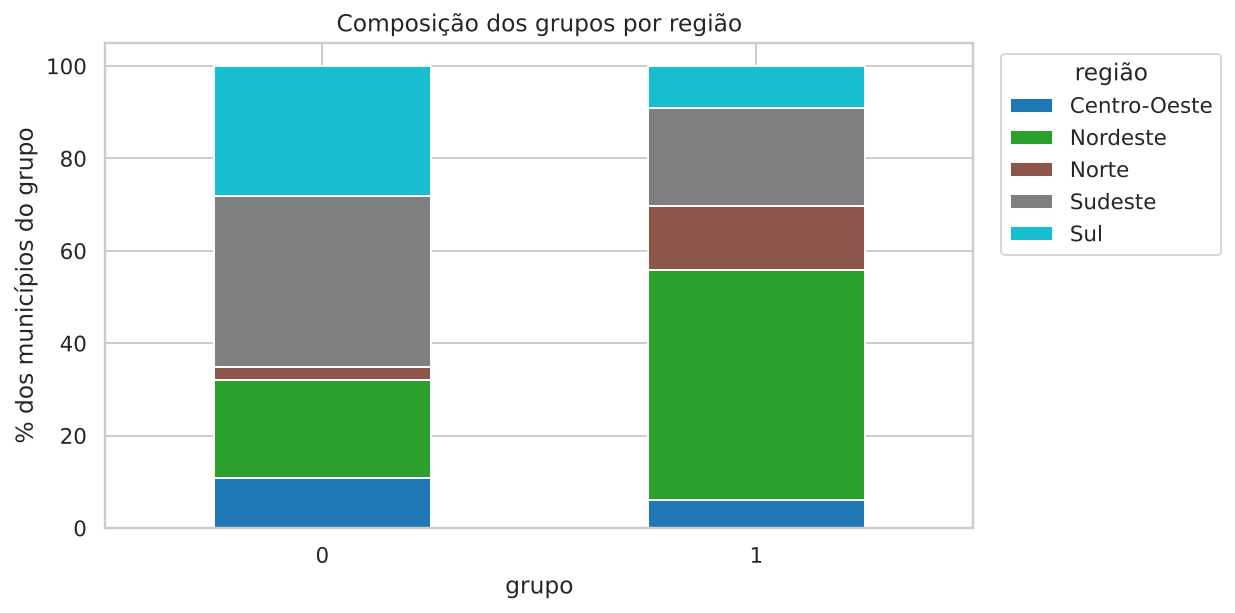

In [7]:
display(pd.read_csv(REPORTS / "silhouette_por_k.csv"))
display(pd.read_csv(REPORTS / "perfil_grupos.csv"))
display(Image(str(IMAGES / "cluster_pca.png"))); display(Image(str(IMAGES / "cluster_composicao_regiao.png")))

## 7. Municípios que podem não atingir metas futuras

In [8]:
print(R["projecao"])
p = REPORTS / "projecao_risco_meta_2025.csv"
if p.exists():
    display(pd.read_csv(p).head(15).round(3))

metas futuras não coletadas (rode external_sources)
